# Bilayer Wigner Crystal: Finding the Ground-State Lattice by Optimization

**Goal.** Reproduce the main results of Figs. 1 and 2 of G. Goldoni and F. M. Peeters, *"Stability, dynamical properties, and melting of a classical bilayer Wigner crystal,"* Phys. Rev. B **53**, 4591–4603 (1996), [doi:10.1103/PhysRevB.53.4591](https://doi.org/10.1103/PhysRevB.53.4591): the static Coulomb energy per particle of a classical bilayer Wigner crystal as a function of the dimensionless interlayer parameter $\eta = d\sqrt{n/2}$ ($d$ is the interlayer distance, $n$ the total areal density), including the soft phases II and IV shown in Fig. 2 — without assuming any lattice geometry in advance.

**What this tutorial covers:**
- Building a fully general, non-hardcoded oblique-cell parameterization for a two-particle bilayer unit cell
- Using JAX autodiff and `optax` to find, by gradient descent, the cell shape *and* the two electron positions that minimize the Coulomb energy computed with `ezwald.bilayer_sum.EwaldSumSlab`
- Validating the result against the paper's known limiting values and its three rigid candidate lattices (Table I, phases I, III and V) — reproduced here from the table, not assumed by the optimizer
- Comparing the optimized energies and lattices with the soft phases II and IV, whose free aspect ratio or angle is fixed by minimizing the Table I geometry
- Checking that the optimizer recovers not just the right energy but the right lattice geometry for all five phases, using 2D lattice ("Lagrange") reduction to compare bases independent of orientation

The paper's own approach is to write down five candidate lattices and compare their energies by hand. Here, the optimizer is given only random starting positions for the two particles (one per layer), random starting cell shapes and a value of $\eta$, and is left to discover the ground-state structure on its own.

**Contents:** 1–4 method, 5 sanity checks, 6 $\eta$ sweep, 7 assumed reference curves, 8 comparison chart colored by phase, with a lattice inset for each of the five phases, 9 do the optimized structures match the assumed lattices, 10 the optimizer also finds the soft phases.

**Requirements:** `ezwald`, `jax`, `optax`, `numpy`, `matplotlib`. Runs in a couple of minutes on CPU.

In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'
import jax
jax.config.update("jax_enable_x64", True)

import numpy as np
import jax.numpy as jnp
import optax
import matplotlib.pyplot as plt

from ezwald import bilayer_sum, geometry as geo

np.set_printoptions(precision=6, suppress=True)

## 1. Physical conventions

We follow the paper's conventions: total areal density $n=1$, $e=1$, so the energy per particle computed by EZwald is directly the dimensionless quantity $E/(e^2\sqrt n)$ plotted in the paper's Fig. 1.

The bilayer's primitive cell holds exactly **one particle per layer** (Eqs. 1–2 of the paper), so for a given total density $n$ the in-plane cell area is fixed by

$$
n_s = n/2 = \frac{1}{A_{\text{cell}}} \quad\Rightarrow\quad A_{\text{cell}} = \frac{2}{n},
$$

and the interlayer distance for a target $\eta$ is $d = \eta/\sqrt{n_s}$. Together with the one-particle-per-layer cell, this area constraint is the *only* physics we build in by hand — it fixes the density, not the lattice shape. Everything about the shape of the cell and the relative position of the two particles is left to the optimizer.

In [2]:
n_total = 1.0                 # total areal density n (both layers), e = 1
n_s = n_total / 2.0            # density of each sublattice
area = 2.0 / n_total           # in-plane primitive-cell area fixed by n_s = 1/area
aref = float(np.sqrt(area))    # a reference length scale, used only to set search ranges

def eta_to_d(eta):
    return eta / np.sqrt(n_s)

## 2. A generic (non-hardcoded) parameterization of the bilayer cell

Instead of picking one of the five named Bravais lattices, we describe *any* 2D oblique cell of fixed area with two free numbers, $a$ and $\theta$:

$$
\mathbf a_1 = (a,\,0), \qquad
\mathbf a_2 = (b\cos\theta,\, b\sin\theta), \qquad
b = \frac{A_{\text{cell}}}{a\sin\theta},
$$

so that $|\mathbf a_1\times\mathbf a_2| = A_{\text{cell}}$ exactly, for *any* choice of $a,\theta$. This single family already contains all five of the paper's phases as special cases (e.g. $\theta=90^\circ$ with the right $a$ gives the rectangular cells of phases I, II and III; $\theta=60^\circ$ gives the staggered hexagonal phase V; intermediate angles give the rhombic phase IV). We never tell the optimizer which one to pick.

The two particle positions — one per layer — are stored as free **fractional** coordinates `pos_frac`, shape `(2, 2)`, converted to Cartesian via `pos_frac @ cell`. `pos_frac[0]` is the layer-A particle, `pos_frac[1]` is the layer-B particle; nothing pins either of them to a particular value.

`a` and `theta` are optimized in an unconstrained space and mapped through a `sigmoid` into a generous-but-finite range. This is *not* a physics assumption about which phase wins — it only keeps the cell from collapsing into a numerically degenerate sliver during gradient descent (an Ewald sum's real/reciprocal split becomes ill-conditioned for extremely skewed cells). The range is wide enough to contain the lattices of all five phases, and we verify this below (Sections 8 and 9) by checking that the optimizer recovers their energies and lattice geometries.

In [3]:
THETA_MIN, THETA_MAX = jnp.deg2rad(40.0), jnp.deg2rad(140.0)
A_MIN, A_MAX = 0.55 * aref, 1.8 * aref

def unpack_params(params):
    '''Map unconstrained (raw_a, raw_theta) into a bounded, well-conditioned cell.'''
    a = A_MIN + (A_MAX - A_MIN) * jax.nn.sigmoid(params['raw_a'])
    theta = THETA_MIN + (THETA_MAX - THETA_MIN) * jax.nn.sigmoid(params['raw_theta'])
    return a, theta, params['pos_frac']

def make_cell(area, a, theta):
    '''Build a fixed-area oblique cell from free parameters (a, theta).'''
    b = area / (a * jnp.sin(theta))
    return jnp.stack([
        jnp.stack([a, 0.0 * a]),
        jnp.stack([b * jnp.cos(theta), b * jnp.sin(theta)]),
    ])

def random_init(key):
    '''Random starting guess: unconstrained (a, theta) plus two random fractional positions.'''
    k1, k2, k3 = jax.random.split(key, 3)
    raw_a = jax.random.uniform(k1, (), minval=-1.5, maxval=1.5)
    raw_theta = jax.random.uniform(k2, (), minval=-1.5, maxval=1.5)
    pos_frac = jax.random.uniform(k3, (2, 2))  # the two starting positions, one per layer
    return {'raw_a': raw_a, 'raw_theta': raw_theta, 'pos_frac': pos_frac}

## 3. Energy of a candidate configuration

Given `params` (cell shape + the two positions) and the interlayer distance `d` for this $\eta$, the loss is the dimensionless bilayer Coulomb energy per particle from EZwald's `bilayer_sum.EwaldSumSlab`, evaluated on a cell and positions that come from the optimizer rather than from a table of lattice vectors.

Two implementation details make this differentiable and numerically stable while the cell keeps changing shape during gradient descent:

* **Reciprocal G-vectors as `gidx @ recvec(cell)`.** `EwaldSumSlab`'s own G-point selection uses a boolean-mask filter, which can be neither differentiated nor vectorized with `jax.vmap`. We instead pick the integer G indices once (from a reference cell), then recompute the actual G-vectors from the *current* cell at every step — differentiable, and cheap.
* **A fixed Ewald `alpha`,** also taken from the reference cell rather than re-guessed from whatever (possibly transiently skewed) cell the optimizer is currently visiting. In our tests, letting `alpha` adjust to a transiently degenerate cell produced spurious large negative energies; keeping it fixed gives a stable, convergent optimization.

In [4]:
charge = -jnp.ones(2)  # both particles carry charge -1 (in units of e)

def build_ewald_reference(d, n_lat=2):
    '''Pick a reference (square, well-conditioned) cell just to fix the G-index set and alpha.'''
    cell0 = np.array([[aref, 0.0], [0.0, aref]])
    trial = bilayer_sum.EwaldSumSlab(cell0, float(d), disp_fn_mode='general', n_lat=n_lat)
    recvec0 = geo.calc_recvec(jnp.asarray(cell0))
    gidx = np.array(np.round(trial.gpoints @ np.linalg.inv(np.asarray(recvec0))), dtype=int)
    return jnp.asarray(gidx), float(trial.alpha)

def make_loss(d, gidx, alpha, n_lat=2):
    def loss_fn(params):
        a, theta, pos_frac = unpack_params(params)
        cell = make_cell(area, a, theta)
        recvec = geo.calc_recvec(cell)
        gpoints = gidx @ recvec  # differentiable w.r.t. the current cell
        bew = bilayer_sum.EwaldSumSlab(
            cell, d, disp_fn_mode='general', gpoints=gpoints, alpha=alpha, n_lat=n_lat,
        )
        pos = pos_frac @ cell  # fractional -> Cartesian, for BOTH layer positions
        E_total = bew.energy(charge, pos)
        return (E_total / 2.0) / jnp.sqrt(n_total)  # E per particle, dimensionless
    return loss_fn

## 4. Optimizing at a single $\eta$

Gradient descent from one starting pair of positions only ever finds *a* local minimum — and since we've deliberately not told it which phase to expect, that local minimum could belong to any of the (generally several) locally-stable geometries at this $\eta$. So for each $\eta$ we launch several independent optimizations from different random starting positions and cell shapes, run each with Adam (exponential-decay learning-rate schedule, gradient clipping), and keep whichever run reaches the lowest energy. This multi-start search stands in for prior knowledge of the phase diagram: the restarts, not any assumed lattice, are what let the equilibrium structure emerge on its own.

All restarts for a given $\eta$ are optimized simultaneously with a single `vmap`+`jit`'d `lax.scan`, so the whole batch of gradient-descent trajectories runs as one compiled call.

In [5]:
def optimize_eta(eta, key, n_restarts=8, nstep=500):
    '''Relax the bilayer cell + two positions at fixed eta; return the lowest energy found.'''
    d = eta_to_d(eta)
    gidx, alpha = build_ewald_reference(d)
    loss_fn = make_loss(d, gidx, alpha)
    grad_fn = jax.value_and_grad(loss_fn)

    schedule = optax.exponential_decay(init_value=0.1, transition_steps=200, decay_rate=0.5)
    optimizer = optax.chain(optax.clip(1.0), optax.adam(schedule))

    def run_opt(params, opt_state):
        def scan_step(carry, _):
            params, opt_state = carry
            _, grads = grad_fn(params)
            updates, opt_state = optimizer.update(grads, opt_state, params)
            params = optax.apply_updates(params, updates)
            return (params, opt_state), None
        (params, opt_state), _ = jax.lax.scan(scan_step, (params, opt_state), None, length=nstep)
        return params

    keys = jax.random.split(key, n_restarts)
    params0 = jax.vmap(random_init)(keys)               # the batch of "2 starting positions" + cells
    opt_state0 = jax.vmap(optimizer.init)(params0)

    final_params = jax.jit(jax.vmap(run_opt))(params0, opt_state0)
    final_energy = jax.vmap(loss_fn)(final_params)
    final_energy = jnp.where(jnp.isnan(final_energy), jnp.inf, final_energy)
    best = jnp.argmin(final_energy)
    return float(final_energy[best]), final_params, best

## 5. Sanity checks against the paper's known limits

Before sweeping the full range, we check the optimizer against two limits where the paper gives the energy — with no lattice hardcoded anywhere in the optimization itself:

* $\eta\to0$: should approach the single-layer hexagonal Wigner crystal value $E/(e^2\sqrt n)=-1.96052$. We test at $\eta=0.001$, not exactly 0, so the paper's small-$\eta$ series (Eq. 16) gives the expected value there.
* $\eta\to\infty$: two decoupled hexagonal lattices of half density, $E/(e^2\sqrt n)\to-1.96052/\sqrt2\approx-1.38630$.

In [6]:
def eq16(eta):
    '''Small-eta series for the energy per particle, Eq. 16 of the paper.'''
    return -1.96052 + (1 / (2 * np.sqrt(2))) * (2 * np.pi * eta - 0.600434 * eta**2 + 2.86713 * eta**4)

key = jax.random.PRNGKey(0)

k1, key = jax.random.split(key)
e_small, _, _ = optimize_eta(0.001, k1)
print(f"eta=0.001 (-> eta=0 limit):   optimized = {e_small:.5f}   paper Eq. 16 = {eq16(0.001):.5f}   (eta=0 value: -1.96052)")

k1, key = jax.random.split(key)
e_large, _, _ = optimize_eta(10.0, k1)
print(f"eta=10    (-> eta=inf limit): optimized = {e_large:.5f}   asymptote = {-1.96052/np.sqrt(2):.5f}")

eta=0.001 (-> eta=0 limit):   optimized = -1.95830   paper Eq. 16 = -1.95830   (eta=0 value: -1.96052)


eta=10    (-> eta=inf limit): optimized = -1.38629   asymptote = -1.38630


The $\eta\to\infty$ limit is reproduced to about 5 significant figures (compare the two printed values). At small $\eta$ the optimized energy sits slightly above the $\eta=0$ value (by ~0.1%), which is the finite-$\eta$ effect rather than an error: the paper's small-$\eta$ series (Eq. 16), printed alongside, agrees with the optimizer to about the printed precision. In both cases the optimizer was given nothing but random starting positions and cell shapes, within a deliberately loose bound on the cell shape.

## 6. Sweeping $\eta$

We sweep $\eta$ from 0.01 to 1 (the range plotted in the paper's Fig. 1; we start just above 0 because $\eta=0$ puts both layers on top of each other, a degenerate starting point) using 40 points, and optimize at each one.

In [7]:
eta_opt = np.linspace(0.01, 1.0, 40)

energies_opt = np.zeros_like(eta_opt)
key = jax.random.PRNGKey(1)
for i, eta in enumerate(eta_opt):
    key, subkey = jax.random.split(key)
    energies_opt[i], _, _ = optimize_eta(eta, subkey)

print("done:", len(eta_opt), "eta points optimized")

done: 40 eta points optimized


## 7. Assumed reference curves from Table I of the paper

For comparison we also compute the energy of the paper's three *rigid* phases — I (one-component hexagonal), III (staggered square) and V (staggered hexagonal) — directly from the primitive vectors $\mathbf a_1,\mathbf a_2$ and interlayer displacement $\mathbf c$ tabulated in Table I. This part *does* hardcode the lattice geometry, because that is what Table I is; its only purpose is to draw the comparison curves, and it plays no role in the optimization above. (Phases II and IV have a free aspect ratio or angle that the paper minimizes separately, so Table I does not fix a single geometry for them; their assumed lattices are built in Section 8.)

In [8]:
PHASE_TABLE = {
    "I": dict(
        a1=lambda a: np.array([a, 0.0]),
        a2=lambda a: np.array([0.0, np.sqrt(3) * a]),
        c=lambda a1, a2: (a1 + a2) / 2,
        nsa2=1 / np.sqrt(3),
    ),
    "III": dict(
        a1=lambda a: np.array([a, 0.0]),
        a2=lambda a: np.array([0.0, a]),
        c=lambda a1, a2: (a1 + a2) / 2,
        nsa2=1.0,
    ),
    "V": dict(
        a1=lambda a: np.array([a, 0.0]),
        a2=lambda a: np.array([0.5 * a, np.sqrt(3) / 2 * a]),
        c=lambda a1, a2: (a1 + a2) / 3,
        nsa2=2 / np.sqrt(3),
    ),
}


def build_phase_cell(phase, n_total=1.0):
    entry = PHASE_TABLE[phase]
    n_s = n_total / 2.0
    a = np.sqrt(entry["nsa2"] / n_s)
    a1 = entry["a1"](a)
    a2 = entry["a2"](a)
    c = entry["c"](a1, a2)
    return np.array([a1, a2]), c, a


def reference_dimensionless_energy(phase, eta, n_total=1.0):
    latvec, c, a = build_phase_cell(phase, n_total=n_total)
    n_s = n_total / 2.0
    d = eta / np.sqrt(n_s)
    bew = bilayer_sum.EwaldSumSlab(latvec, float(d))
    pos = jnp.array([[0.0, 0.0], c])
    ch = -jnp.ones(2)
    return float(bew.energy(ch, pos) / 2.0 / np.sqrt(n_total))


def lattice_patch(latvec, c, nrep=3):
    ii, jj = np.meshgrid(np.arange(-nrep, nrep + 1), np.arange(-nrep, nrep + 1))
    ij = np.stack([ii.ravel(), jj.ravel()], axis=-1)
    R = ij @ latvec
    return R, R + c


eta_vals = np.linspace(0.0, 1.0, 200)
energies_ref = {
    phase: np.array([reference_dimensionless_energy(phase, eta) for eta in eta_vals])
    for phase in PHASE_TABLE
}
for phase in PHASE_TABLE:
    print(f"phase {phase}: E(eta=0)={energies_ref[phase][0]:.5f}   E(eta=1)={energies_ref[phase][-1]:.5f}")

phase I: E(eta=0)=-1.96052   E(eta=1)=-1.31491
phase III: E(eta=0)=-1.95013   E(eta=1)=-1.38145
phase V: E(eta=0)=-1.89371   E(eta=1)=-1.38744


## 8. Comparison chart

The chart plots the optimized energy sweep against the assumed phase I/III/V curves (black). The optimized curve is colored by phase, using the $\eta$ range in which Goldoni and Peeters (Sec. I) find each phase to be the ground state: I for $\eta<0.006$, II for $0.006<\eta<0.262$, III for $0.262<\eta<0.622$, IV for $0.622<\eta<0.732$ and V for $\eta>0.732$. It is drawn *under* the black curves, so any real deviation shows up as color poking out from behind them. The sweep starts at $\eta=0.01$, so no sweep point falls inside phase I's narrow range; the optimized energy at the phase I inset's $\eta=0.004$ is drawn as a single point in phase I's color instead.

Five insets show lattice geometry. The black dots (layer A) and crosses (layer B) are the Table I lattice of each phase, and the red dots/crosses are the structure the optimizer actually found at one $\eta$ value, tiled the same way. Phases II and IV each have one free parameter in Table I (the aspect ratio $a_2/a_1$ for II and the angle $\theta$ between $\mathbf a_1$ and $\mathbf a_2$ for IV), so their black lattice uses the value of that parameter that minimizes the energy at the inset's $\eta$. No black energy curve is drawn for II or IV.

The five marked $\eta$ values ($0.004,\ 0.10,\ 0.47,\ 0.65,\ 0.82$) are illustrative locations, not phase-transition points. The black filled circles mark the energy of each assumed lattice at that $\eta$, and the red rings mark the corresponding points on the optimized curve.

In [9]:
# Ground-state eta range of each phase, from Sec. I of Goldoni and Peeters (p. 4594).
PHASE_RANGES = [
    ("I", 0.0, 0.006),
    ("II", 0.006, 0.262),
    ("III", 0.262, 0.622),
    ("IV", 0.622, 0.732),
    ("V", 0.732, np.inf),
]
PHASE_COLORS = {"I": "#E69F00", "II": "#56B4E9", "III": "#009E73", "IV": "#CC79A7", "V": "#0072B2"}


def phase_at(eta):
    for phase, lo, hi in PHASE_RANGES:
        if lo <= eta < hi:
            return phase


# Soft phases II and IV (Table I) each have one free parameter: the aspect ratio
# xi = a2/a1 for II and the angle theta between a1 and a2 for IV. Their assumed
# lattice at a given eta is the Table I geometry with that parameter chosen to
# minimize the energy, found here by a refined 1D grid search.
SOFT_PARAM_RANGE = {"II": (1.0, np.sqrt(3.0)), "IV": (np.radians(60.0), np.radians(90.0))}


def build_soft_phase_cell(phase, param, n_total=1.0):
    n_s = n_total / 2.0
    if phase == "II":
        a = np.sqrt(1.0 / (param * n_s))
        a1, a2 = np.array([a, 0.0]), np.array([0.0, param * a])
    else:
        a = np.sqrt(1.0 / (n_s * np.sin(param)))
        a1, a2 = np.array([a, 0.0]), a * np.array([np.cos(param), np.sin(param)])
    return np.array([a1, a2]), (a1 + a2) / 2, a


def soft_phase_energy(phase, param, eta, n_total=1.0):
    latvec, c, _ = build_soft_phase_cell(phase, param, n_total=n_total)
    d = eta / np.sqrt(n_total / 2.0)
    bew = bilayer_sum.EwaldSumSlab(latvec, float(d))
    pos = jnp.array([[0.0, 0.0], c])
    return float(bew.energy(-jnp.ones(2), pos) / 2.0 / np.sqrt(n_total))


def minimize_soft_phase(phase, eta, n_grid=21, n_refine=4):
    lo, hi = SOFT_PARAM_RANGE[phase]
    for _ in range(n_refine):
        grid = np.linspace(lo, hi, n_grid)
        E = np.array([soft_phase_energy(phase, p, eta) for p in grid])
        k = int(np.argmin(E))
        lo, hi = grid[max(k - 1, 0)], grid[min(k + 1, n_grid - 1)]
    return grid[k], E[k]


def add_lattice_inset(ax, bounds, latvec, c, a, nrep=2):
    inset = ax.inset_axes(bounds)
    RA, RB = lattice_patch(latvec, c, nrep=nrep)
    inset.plot(*RA.T, ls="", marker=".", color="k", ms=5)
    inset.plot(*RB.T, ls="", marker="x", color="k", ms=4, mew=1.0)
    lim = (nrep - 0.3) * a
    inset.set_xlim(-lim, lim)
    inset.set_ylim(-lim, lim)
    inset.set_aspect(1)
    inset.set_xticks([])
    inset.set_yticks([])
    for spine in inset.spines.values():
        spine.set_linewidth(0.8)
    return inset


def inset_right_edge_label(ax, bounds, text):
    x0, y0, w, h = bounds
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    data_x = xlim[0] + (x0 + w + 0.015) * (xlim[1] - xlim[0])
    data_y = ylim[0] + (y0 + h / 2) * (ylim[1] - ylim[0])
    ax.text(data_x, data_y, text, fontsize=12, fontweight="bold", ha="left", va="center")


PHASES = ["I", "II", "III", "IV", "V"]
inset_bounds = {
    "I": [0.10, 0.03, 0.16, 0.22],
    "II": [0.21, 0.32, 0.16, 0.22],
    "III": [0.12, 0.72, 0.16, 0.22],
    "IV": [0.51, 0.53, 0.16, 0.22],
    "V": [0.77, 0.60, 0.16, 0.22],
}

eta_by_phase = {
    "I": 0.004,   # inside phase I's stability window, eta < 0.006
    "II": 0.10,
    "III": 0.47,
    "IV": 0.65,
    "V": 0.82,
}

# Assumed (Table I) lattice and energy at each marked eta.
assumed_cells, assumed_energies, soft_params = {}, {}, {}
for phase in PHASES:
    eta = eta_by_phase[phase]
    if phase in ("II", "IV"):
        soft_params[phase], assumed_energies[phase] = minimize_soft_phase(phase, eta)
        assumed_cells[phase] = build_soft_phase_cell(phase, soft_params[phase])
    else:
        assumed_cells[phase] = build_phase_cell(phase)
        assumed_energies[phase] = reference_dimensionless_energy(phase, eta)

print(f"phase II at eta={eta_by_phase['II']:.2f}: a2/a1 = {soft_params['II']:.3f}")
print(f"phase IV at eta={eta_by_phase['IV']:.2f}: theta = {np.degrees(soft_params['IV']):.1f} deg")

phase II at eta=0.10: a2/a1 = 1.660
phase IV at eta=0.65: theta = 78.4 deg


### Extracting the optimized structure

Matching energy isn't proof of matching geometry, so at each inset $\eta$ we take the *winning* restart's relaxed cell and its two electron positions and tile them into a patch in the same way as the assumed insets. For III and IV the red patch extends over more cells, so that the optimized lattice, whose orientation is not fixed, fills the whole inset. Layer B's offset from layer A is wrapped into the unit cell first, so the tiled block lines up with the assumed one.

In [10]:
def optimized_lattice_patch(eta, key, n_restarts=8, nstep=500, nrep=2):
    '''Relax at eta, take the winning restart's cell+positions, and tile a small patch
    of it the same way lattice_patch() does for the assumed phases -- for direct
    visual comparison with the black insets. Also returns the winning energy itself,
    so the exact (eta, E) point this structure was pulled from can be marked.'''
    best_energy, final_params, best = optimize_eta(eta, key, n_restarts=n_restarts, nstep=nstep)
    winner = jax.tree_util.tree_map(lambda leaf: leaf[best], final_params)
    a, theta, pos_frac = unpack_params(winner)
    cell = np.asarray(make_cell(area, a, theta))
    pos_frac = np.asarray(pos_frac)

    ii, jj = np.meshgrid(np.arange(-nrep, nrep + 1), np.arange(-nrep, nrep + 1))
    ij = np.stack([ii.ravel(), jj.ravel()], axis=-1)
    # Layer A sits at the origin (translation gauge choice). Layer B's offset from A
    # is wrapped into [0, 1) in fractional coordinates before tiling, so the same
    # block of cells (ij = -nrep..nrep) is drawn as in the black Table-I inset, whose
    # shift c is also inside the unit cell. Without the wrap, the optimizer's raw
    # offset can differ from c by a lattice vector, which shifts the red block by a
    # cell relative to the black one and leaves stray black points at the edge.
    frac_shift = (pos_frac[1] - pos_frac[0]) % 1.0
    RA = ij @ cell
    RB = ij @ cell + frac_shift @ cell
    return RA, RB, cell, best_energy

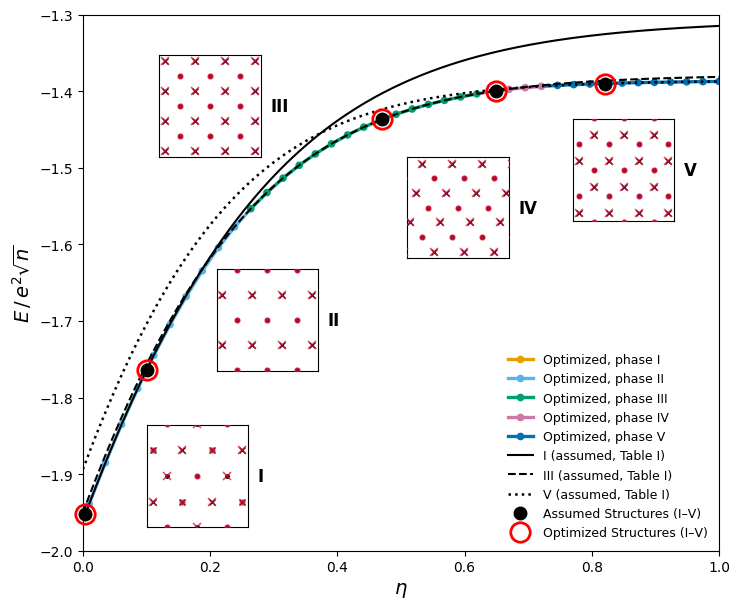

In [11]:
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D

fig, ax = plt.subplots(figsize=(7.5, 6.2))

# Optimized sweep, colored by the phase the paper assigns to each eta. Each line
# segment takes the color of the phase at its midpoint. It is drawn at the lowest
# z-order so the black assumed curves sit on top of it, and any real deviation
# shows up as color poking out from behind the black lines.
points = np.column_stack([eta_opt, energies_opt])
segments = np.stack([points[:-1], points[1:]], axis=1)
seg_colors = [PHASE_COLORS[phase_at(0.5 * (e0 + e1))] for e0, e1 in zip(eta_opt[:-1], eta_opt[1:])]
ax.add_collection(LineCollection(segments, colors=seg_colors, lw=2.4, zorder=1))
ax.scatter(eta_opt, energies_opt, s=20, c=[PHASE_COLORS[phase_at(e)] for e in eta_opt], zorder=1)

ax.plot(eta_vals, energies_ref["I"], color="black", ls="-", lw=1.5, zorder=3)
ax.plot(eta_vals, energies_ref["III"], color="black", ls="--", lw=1.5, zorder=3)
ax.plot(eta_vals, energies_ref["V"], color="black", ls=":", lw=1.8, zorder=3)

ax.set_xlim(0.0, 1.0)
ax.set_ylim(-2.0, -1.3)
ax.set_xlabel(r"$\eta$", fontsize=14)
ax.set_ylabel(r"$E\,/\,e^2\sqrt{n}$", fontsize=14)

# Insets: black = assumed (Table I) lattice, red = the structure the optimizer
# actually found at the same eta, tiled the same way.
structure_key = jax.random.PRNGKey(2024)
optimized_structures = {}
marker_energies = {}
for phase in PHASES:
    latvec, c, a = assumed_cells[phase]
    inset = add_lattice_inset(ax, inset_bounds[phase], latvec, c, a)
    inset_right_edge_label(ax, inset_bounds[phase], phase)
    structure_key, subkey = jax.random.split(structure_key)
    # III and IV need a larger red patch so it fills the whole inset box.
    nrep = 4 if phase in ("III", "IV") else 2
    RA, RB, cell_opt, e_marker = optimized_lattice_patch(eta_by_phase[phase], subkey, nrep=nrep)
    optimized_structures[phase] = (RA, RB, cell_opt)
    marker_energies[phase] = e_marker
    inset.plot(*RA.T, ls="", marker=".", color="crimson", ms=7, alpha=0.75, zorder=4)
    inset.plot(*RB.T, ls="", marker="x", color="crimson", ms=6, mew=1.2, alpha=0.75, zorder=4)

# No sweep point falls inside phase I's narrow range (eta < 0.006), so the optimized
# energy at the phase I inset's eta is drawn in phase I's color instead.
ax.scatter([eta_by_phase["I"]], [marker_energies["I"]], s=20, c=PHASE_COLORS["I"], zorder=2, clip_on=False)

# Filled black circles: the (eta, E) point each black inset lattice was taken from.
ax.plot(
    [eta_by_phase[p] for p in PHASES], [assumed_energies[p] for p in PHASES],
    ls="", marker="o", ms=9, mfc="black", mec="black", mew=1.0, zorder=6, clip_on=False,
)
# Red open circles: the (eta, E) point on the optimized curve each red inset structure was taken from.
ax.plot(
    [eta_by_phase[p] for p in PHASES], [marker_energies[p] for p in PHASES],
    ls="", marker="o", ms=14, mfc="none", mec="red", mew=2.0, zorder=7, clip_on=False,
)

legend_handles = [
    Line2D([], [], color=PHASE_COLORS[p], lw=2.4, marker="o", ms=4.5, label=f"Optimized, phase {p}")
    for p in PHASES
] + [
    Line2D([], [], color="black", ls="-", lw=1.5, label="I (assumed, Table I)"),
    Line2D([], [], color="black", ls="--", lw=1.5, label="III (assumed, Table I)"),
    Line2D([], [], color="black", ls=":", lw=1.8, label="V (assumed, Table I)"),
    Line2D([], [], ls="", marker="o", ms=9, mfc="black", mec="black", label="Assumed Structures (I–V)"),
    Line2D([], [], ls="", marker="o", ms=14, mfc="none", mec="red", mew=2.0, label="Optimized Structures (I–V)"),
]
ax.legend(handles=legend_handles, frameon=False, loc="lower right", fontsize=9)

fig.tight_layout()

## 9. Do the optimized structures match the assumed lattices?

First, the raw cell vectors of the optimized structure next to the assumed cell at each inset $\eta$ (the Table I cell for I, III and V; the energy-minimized Table I geometry for II and IV):

In [12]:
print(f"{'phase':6s} {'eta':>6s}   {'optimized a1':>22s}   {'optimized a2':>22s}   assumed a1 / a2")
for phase in PHASES:
    eta = eta_by_phase[phase]
    _, _, cell_opt = optimized_structures[phase]
    latvec_ref, _, _ = assumed_cells[phase]
    print(f"{phase:6s} {eta:6.3f}   a1={cell_opt[0]}   a2={cell_opt[1]}   "
          f"ref a1={latvec_ref[0]}  a2={latvec_ref[1]}")

phase     eta             optimized a1             optimized a2   assumed a1 / a2
I       0.004   a1=[2.149105 0.      ]   a2=[0.537329 0.93062 ]   ref a1=[1.07457 0.     ]  a2=[0.      1.86121]
II      0.100   a1=[1.097771 0.      ]   a2=[1.097773 1.821874]   ref a1=[1.09777 0.     ]  a2=[0.       1.821875]
III     0.470   a1=[1.41424 0.     ]   a2=[1.414311 1.414187]   ref a1=[1.414214 0.      ]  a2=[0.       1.414214]
IV      0.650   a1=[1.42885 0.     ]   a2=[-1.141863  1.399727]   ref a1=[1.428853 0.      ]  a2=[0.287042 1.399724]
V       0.820   a1=[1.519672 0.      ]   a2=[0.759836 1.316074]   ref a1=[1.519671 0.      ]  a2=[0.759836 1.316074]


Looking at the inset overlays from the run shown here: for phases **II**, **III**, **IV** and **V** the red points land on the black ones. Phase **I**'s red points also coincide with the black ones in position, but not always by layer: at some sites a red cross sits on a black dot or a red dot on a black cross, because the optimized lattice here is rotated by $60°$ from the Table I orientation. The raw vectors above also differ for I and IV, since a lattice has many equivalent choices of primitive vectors. We check these observations quantitatively.

We expect a match up to rotation and choice of basis: nothing in our parameterization anchors the lattice to a particular compass direction, and Coulomb energy is rotationally invariant, so the optimizer is free to land on the same physical lattice at any overall orientation, whereas Table I of the paper tabulates one specific (axis-aligned) orientation. We check this with 2D lattice ("Lagrange") reduction, which puts any basis into a canonical shortest-vectors form independent of the original (possibly rotated/skewed) choice of primitive vectors. The table reports the lengths of the two reduced vectors and the acute angle between them:

In [13]:
def lagrange_reduce(cell):
    '''Canonical shortest-vectors basis of a 2D lattice (rotation/choice independent).'''
    a, b = np.array(cell[0], dtype=float), np.array(cell[1], dtype=float)
    while True:
        if np.linalg.norm(b) < np.linalg.norm(a):
            a, b = b, a
        m = round(np.dot(a, b) / np.dot(a, a))
        if m == 0:
            break
        b = b - m * a
    return a, b


def reduced_shape(cell):
    '''|a|, |b| and the acute angle between them for the reduced basis.'''
    a, b = lagrange_reduce(cell)
    cos_angle = abs(np.dot(a, b)) / (np.linalg.norm(a) * np.linalg.norm(b))
    return np.linalg.norm(a), np.linalg.norm(b), np.degrees(np.arccos(min(cos_angle, 1.0)))


print(f"{'phase':6s} {'|a| optimized':>14s} {'|b| optimized':>14s} {'angle':>8s}   "
      f"{'|a| reference':>14s} {'|b| reference':>14s} {'angle':>8s}")
for phase in PHASES:
    _, _, cell_opt = optimized_structures[phase]
    latvec_ref, _, _ = assumed_cells[phase]
    a1, b1, ang1 = reduced_shape(cell_opt)
    a2, b2, ang2 = reduced_shape(latvec_ref)
    print(f"{phase:6s} {a1:14.5f} {b1:14.5f} {ang1:8.3f}   {a2:14.5f} {b2:14.5f} {ang2:8.3f}")

phase   |a| optimized  |b| optimized    angle    |a| reference  |b| reference    angle
I             1.07461        1.86115   90.000          1.07457        1.86121   90.000
II            1.09777        1.82187   90.000          1.09777        1.82188   90.000
III           1.41419        1.41424   89.997          1.41421        1.41421   90.000
IV            1.42884        1.42885   78.413          1.42885        1.42885   78.411
V             1.51967        1.51967   60.000          1.51967        1.51967   60.000


In [14]:
def interlayer_distances(cell, shift, n=4, nrep=3):
    '''In-plane distances from a layer-A electron to its n nearest layer-B electrons, which are
    independent of the lattice's orientation.'''
    ii, jj = np.meshgrid(np.arange(-nrep, nrep + 1), np.arange(-nrep, nrep + 1))
    ij = np.stack([ii.ravel(), jj.ravel()], axis=-1)
    return np.sort(np.linalg.norm(ij @ cell + shift, axis=1))[:n]

print(f"{'phase':6s} {'optimized layer-B distances':>32s}   {'reference layer-B distances':>32s}")
for phase in PHASES:
    RA, RB, cell_opt = optimized_structures[phase]
    latvec_ref, c_ref, _ = assumed_cells[phase]
    print(f"{phase:6s} {str(interlayer_distances(cell_opt, RB[0] - RA[0])):>32s}   "
          f"{str(interlayer_distances(latvec_ref, c_ref)):>32s}")

phase       optimized layer-B distances        reference layer-B distances
I      [1.074552 1.074552 1.074552 1.074553]   [1.07457 1.07457 1.07457 1.07457]
II     [1.063523 1.063523 1.063524 1.063524]   [1.063523 1.063523 1.063523 1.063523]
III    [0.999975 0.999975 1.000025 1.000025]                      [1. 1. 1. 1.]
IV     [0.903201 0.903201 1.107174 1.107174]   [0.903183 0.903183 1.107195 1.107195]
V      [0.877382 0.877383 0.877383 1.754765]   [0.877383 0.877383 0.877383 1.754765]


**All five phases check out**: once reduced to canonical form, the optimized and assumed lattice vector lengths and angles agree closely (typically to several significant figures) — the red pattern really is the same Bravais lattice as the black one, at most at a different (energy-irrelevant) orientation. For II and IV this also means the optimizer finds the same aspect ratio ($|b|/|a|$) and angle as the energy-minimized Table I geometry, without either parameter being given to it.

Phase I has to be tested inside its own narrow stability window, $\eta<0.006$ (Sec. I and Fig. 5 of the paper), which is why its marker sits at $\eta=0.004$: above that window the soft phase II takes over and the aspect ratio moves away from the Table I value $|b|/|a|=\sqrt3\approx1.73$. Reduced lattice vectors do not describe how the two layers sit relative to each other, so the last table above lists the distances from a layer-A electron to its nearest layer-B electrons, which are independent of orientation; these agree as well, so each layer has been recovered and not just the combined pattern of points. We can also confirm directly that the optimizer's energy at this $\eta$ matches the assumed phase I energy:

In [15]:
eta_I_inset = eta_by_phase["I"]
e_assumed_I = reference_dimensionless_energy("I", eta_I_inset)
e_optimized_I, _, _ = optimize_eta(eta_I_inset, jax.random.PRNGKey(2024))
print(f"eta={eta_I_inset:.3f}   assumed phase I = {e_assumed_I:.6f}   "
      f"optimized (unconstrained) = {e_optimized_I:.6f}   "
      f"difference {e_assumed_I - e_optimized_I:.1e}")

eta=0.004   assumed phase I = -1.951672   optimized (unconstrained) = -1.951672   difference 9.7e-09


## 10. Discussion: the optimizer also finds the soft phases

The optimized curve — obtained with no phase table, no lattice type, and no interlayer displacement ever specified by hand — falls essentially on top of the assumed I/III/V curves across the whole $\eta$ range. In the two ranges where the paper finds the *soft* phases II (staggered rectangular) and IV (staggered rhombic) to be the true ground state — $0.006<\eta<0.262$ and $0.622<\eta<0.732$ — it should sit slightly *below* the best of the three rigid curves, because II and IV have a continuously variable aspect ratio/angle that the rigid Table I geometries do not include. Our parameterization is a fully general fixed-area oblique cell, so the optimizer is free to relax into any aspect ratio or angle without being told these phases exist. The gap is small (the paper itself notes that phases II and IV are "nearly indistinguishable" from I/III/V on the scale of its Fig. 1), but at an interior point of each range it is measurable and in the direction of lower energy:

In [16]:
for phase in ["II", "IV"]:
    eta = eta_by_phase[phase]
    key, subkey = jax.random.split(key)
    e_opt, _, _ = optimize_eta(eta, subkey)
    e_rigid = min(reference_dimensionless_energy(p, eta) for p in PHASE_TABLE)
    print(f"eta={eta:.2f}   optimized={e_opt:.5f}   best of I/III/V={e_rigid:.5f}   "
          f"optimized is lower by {e_rigid - e_opt:.5f}   "
          f"minimized phase {phase}={assumed_energies[phase]:.5f}")

eta=0.10   optimized=-1.76429   best of I/III/V=-1.76408   optimized is lower by 0.00020   minimized phase II=-1.76429


eta=0.65   optimized=-1.39974   best of I/III/V=-1.39960   optimized is lower by 0.00015   minimized phase IV=-1.39974


The last column is the energy of the Table I phase II or IV geometry, minimized over its free parameter (Section 8). It is computed with `EwaldSumSlab`'s own G-vectors and `alpha` rather than the fixed ones used inside the optimizer, and it agrees with the optimized energy to the printed precision, so the gap below the rigid phases is not an artifact of the fixed-G, fixed-`alpha` setup.

The same optimization loop that reproduces the three rigid phases also finds, with no extra code, the lower energy of the two soft phases, which a fixed table of rigid lattices cannot represent. Together with the lattice comparison in Section 9, we believe this shows that the optimizer finds phases II and IV without being told they exist, purely by letting gradient descent explore the space of 2D bilayer lattices at each value of $\eta$.

## Conclusion

Given nothing but random starting positions and cell shapes (two particles, one per layer) and a value of $\eta$ — no phase table, no lattice type, and no interlayer displacement specified by hand — gradient-based optimization follows the lowest-energy structure across the full $\eta$ range. The structures themselves also check out: at $\eta=0.004,\ 0.10,\ 0.47,\ 0.65$ and $0.82$, inside the ground-state ranges of phases I, II, III, IV and V respectively, the optimized and assumed lattice vectors and layer offsets agree once compared in a canonical (orientation-independent) form. Where the paper's *soft* phases II and IV become the ground state, the same unconstrained optimizer finds a measurably lower energy than any of the rigid Table I geometries, purely by exploring the space of general 2D bilayer lattices — a result the fixed rigid-lattice table cannot represent on its own.